# Soft Segmentation Tutorial (SMURF-lite)

This notebook demonstrates the SMURF-lite workflow on the 10x FFPE mouse brain Visium HD dataset. SMURF-lite is the non-deep-learning mode of SMURF and does not require a GPU. In the shared-spot transcript-assignment step, SMURF-lite uses a spatial-distance-weighted multinomial strategy. Use the full tutorial instead if you want the deep-learning refinement.

### Dataset Information

Access the dataset here: [Visium HD CytAssist Gene Expression Libraries of Mouse Brain](https://www.10xgenomics.com/datasets/visium-hd-cytassist-gene-expression-libraries-of-mouse-brain-he)

### Important Downloads

To download the necessary files, run the following commands:

```python
# Download data from 10x
!mkdir -p "smurf_example_data"
!wget -P smurf_example_data https://cf.10xgenomics.com/samples/spatial-exp/3.0.0/Visium_HD_Mouse_Brain/Visium_HD_Mouse_Brain_tissue_image.tif
!wget -P smurf_example_data https://cf.10xgenomics.com/samples/spatial-exp/3.0.0/Visium_HD_Mouse_Brain/Visium_HD_Mouse_Brain_binned_outputs.tar.gz
!tar -xzvf smurf_example_data/Visium_HD_Mouse_Brain_binned_outputs.tar.gz -C smurf_example_data

# Download our nuclei segmentation results if needed
!curl -L -o smurf_example_data/segmentation_final.npy.gz https://github.com/The-Mitra-Lab/SMURF/raw/main/data/segmentation_final.npy.gz
!gunzip smurf_example_data/segmentation_final.npy.gz
```

If you use the same cell segmentation method as introduced, you may skip the first part until the section labeled [Start here](https://the-mitra-lab.github.io/SMURF/tutorials/notebooks/Tutorial_Mousebrain.html#Start-here-optional-shortcut)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scanpy as sc
import anndata

import smurf as su

import pickle
import copy
import gzip

> **Note on software versions**
>
> This tutorial was developed and tested with the exact package versions listed below.  
> Using these versions should reproduce the results exactly.  
> Newer releases may introduce subtle differences.  
> If you encounter any issues, please open an issue on our [GitHub repository](https://github.com/The-Mitra-Lab/SMURF/issues) and we’ll respond as soon as possible. Thanks!

| Package        | Version        |
|----------------|----------------|
| numpy          | 1.26.4         |
| pandas         | 1.5.3          |
| tqdm           | 4.66.2         |
| scanpy         | 1.10.0         |
| scipy          | 1.12.0         |
| matplotlib     | 3.8.3          |
| numba          | 0.59.0         |
| scikit-learn   | 1.4.1.post1    |
| Pillow         | 10.2.0         |
| anndata        | 0.10.6         |
| h5py           | 3.10.0         |
| pyarrow        | 16.1.0         |
| igraph         | 0.11.5         |

Here are the python codes you can use to install the exact versions:
```python
import importlib.metadata as metadata
import subprocess
import sys

# Dictionary of desired package versions
desired_versions = {
    "numpy": "1.26.4",
    "pandas": "1.5.3",
    "tqdm": "4.66.2",
    "scanpy": "1.10.0",
    "scipy": "1.12.0",
    "matplotlib": "3.8.3",
    "numba": "0.59.0",
    "scikit-learn": "1.4.1.post1",
    "Pillow": "10.2.0",
    "anndata": "0.10.6",
    "h5py": "3.10.0",
    "pyarrow": "16.1.0",
    "igraph": "0.11.5",
}

for pkg, target_ver in desired_versions.items():
    try:
        installed_ver = metadata.version(pkg)
    except metadata.PackageNotFoundError:
        installed_ver = None

    if installed_ver != target_ver:
        print(f"{pkg} current version: {installed_ver or 'not installed'}, installing/upgrading to {target_ver}…")
        subprocess.run(
            [sys.executable, "-m", "pip", "install", f"{pkg}=={target_ver}"],
            check=True
        )
    else:
        print(f"{pkg} is already at version {target_ver}, no action needed.")
```


Here, we define your data path and saving path. Ensure that your data path includes the complete HE or DAPI image and a folder containing `square_002um` data. Specifically, you will need `tissue_positions.parquet` and `filtered_feature_bc_matrix`.


In [2]:
import os

data_path = 'smurf_example_data/'
save_path = 'results_example_mousebrain/'

# Check if the directory exists
if not os.path.exists(save_path):
    # If it doesn't exist, create it
    os.makedirs(save_path)


We start building our So (spatial object). The input should be your `tissue_positions.parquet` in `'square_002um/spatial'`, the final full image, and the format of your experiment (either `'HE'` or `'DAPI'`).

In [3]:
so = su.prepare_dataframe_image(data_path+'binned_outputs/square_002um/spatial/tissue_positions.parquet',
                                data_path+'Visium_HD_Mouse_Brain_tissue_image.tif',
                               'HE')

Please use your own tools to perform cell segmentation on `so.image_temp()` (the area covered by Visium HD in the original image). Set all background pixels to `0` and assign each cell a unique integer cell ID. `segmentation_final` should be a NumPy array with the same shape as `so.image_temp()`.

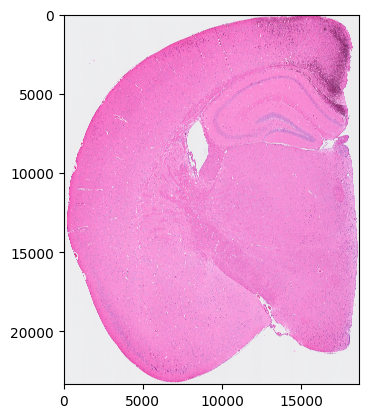

In [4]:
plt.imshow(so.image_temp())
plt.show()
plt.close()

Please save the image for segmentation now.

In [5]:
with gzip.GzipFile(data_path + 'image_to_segmentation.npy.gz', 'w') as f:
    np.save(f, so.image_temp())

Assuming we now have the final segmentation results, let's proceed to read them. You can always use the provided example results to try out the tutorial.

In [6]:
so.segmentation_final = np.load(data_path + 'segmentation_final.npy')

Now, we start generating cell and spot information to prepare for the analysis.


In [7]:
so.generate_cell_spots_information()

Generating cells information.


100%|██████████| 23340/23340 [01:09<00:00, 337.90it/s]


Generating spots information.


100%|██████████| 23340/23340 [02:58<00:00, 131.01it/s]


Filtering cells
We have 57300 nuclei in total.
Creating NN network


Visualize the nuclei segmentation results overlaid on the original HE or DAPI image. Ensure that the results are meaningful and that the segmented nuclei accurately align with the original image.

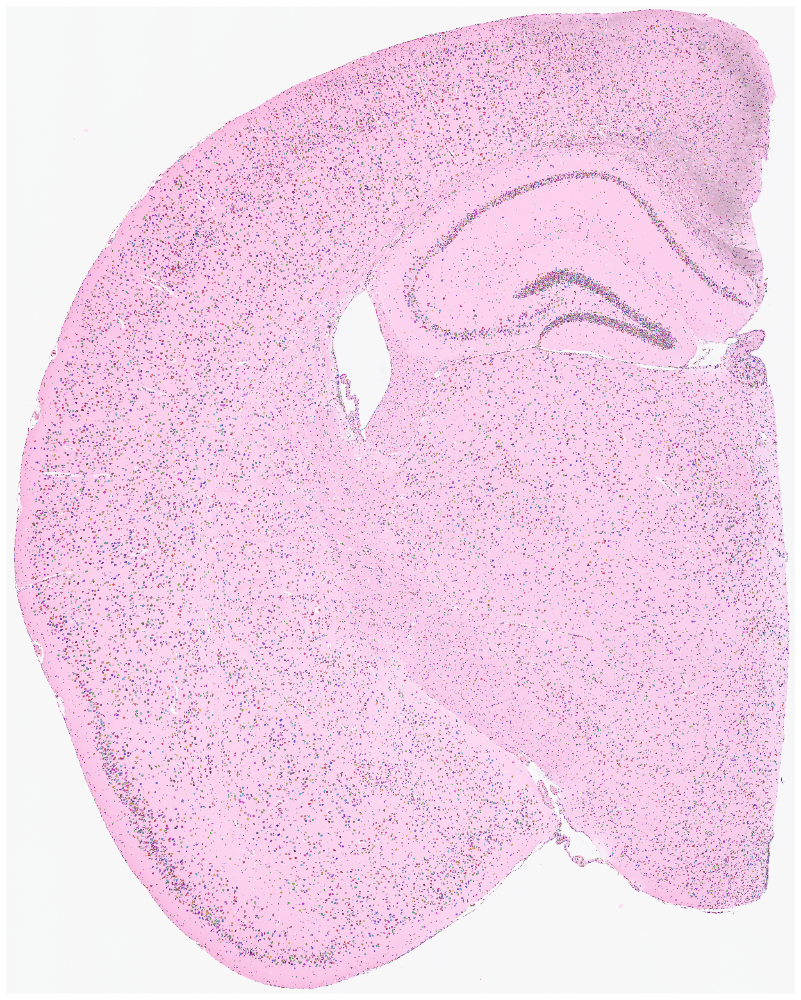

In [8]:
su.plot_results(so.image_temp(), so.segmentation_final )

## Start here (optional shortcut)

Use this section only if you already saved a prepared `so.pkl` object from a previous run, or downloaded a prepared example object. Otherwise, continue from the beginning of the notebook.


```python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scanpy as sc
import anndata

import smurf as su

import pickle
import copy


with open(save_path + 'so.pkl', 'rb') as file:
    so = pickle.load(file)

```


Load `adata` from the original 2 μm results.

In [9]:
# load adata from original 2um results

adata = sc.read_10x_mtx(data_path +'binned_outputs/square_002um/filtered_feature_bc_matrix')
adata = copy.deepcopy(adata[so.df[so.df.in_tissue == 1]['barcode']])
adata.obs

""
s_002um_02448_01644-1
s_002um_00700_02130-1
s_002um_00305_01021-1
s_002um_02703_00756-1
s_002um_02278_00850-1
...
s_002um_02189_01783-1
s_002um_01609_01578-1
s_002um_00456_02202-1
s_002um_00292_01011-1


In [10]:
sc.pp.filter_genes(adata, min_counts=1000) 

Here, we begin by generating the `nuclei*genes` matrix. The result will be stored in `so.final_nuclei`.

In [11]:
su.nuclei_rna(adata,so)
adata_sc = copy.deepcopy(so.final_nuclei)
adata_sc

100%|██████████| 57300/57300 [01:10<00:00, 807.64it/s] 


AnnData object with n_obs × n_vars = 57300 × 9970
    var: 'gene_ids', 'feature_types'

Filter cells by counts while preserving the raw data version.

In [12]:
sc.pp.filter_cells(adata_sc, min_counts=5)
adata_raw = copy.deepcopy(adata_sc)
adata_raw 

AnnData object with n_obs × n_vars = 56867 × 9970
    obs: 'n_counts'
    var: 'gene_ids', 'feature_types'

In [13]:
adata_raw = copy.deepcopy(adata_sc)

Initial analysis of nuclei data. Note that many datasets may not perform well at this stage; it is normal to observe hundreds of clusters due to low-quality nuclei counts.

### Note on the clustering resolution used below

In `su.singlecellanalysis(..., resolution=2)`, `resolution` refers to the Leiden clustering resolution used for nuclei-level initialization. We use 2.0 as the default starting value in this tutorial. Lower values generally merge clusters, whereas higher values tend to split clusters. If you observe obvious over-splitting, try a lower value; if distinct populations are merged, try a higher value.

Starting mt
Starting normalization
Starting PCA
Starting UMAP


/home/juanru/miniconda3/envs/bidcell/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Starting Clustering


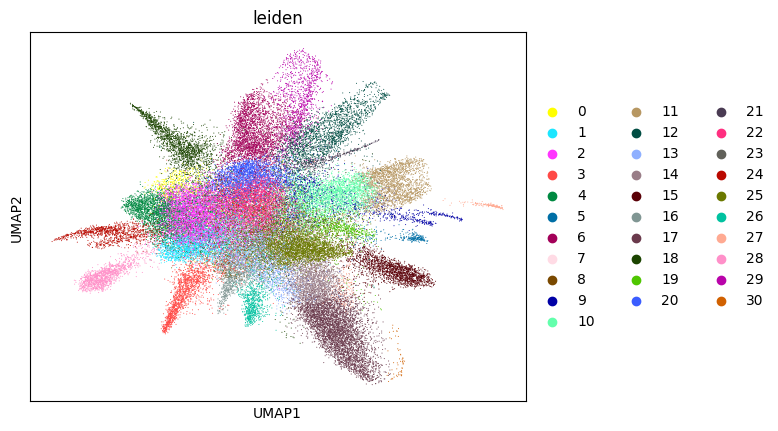

In [14]:
adata_sc = su.singlecellanalysis(adata_sc,resolution=2)

Here, we start performing iterations. Note that this function can be time-consuming.

100%|██████████| 56867/56867 [01:06<00:00, 860.10it/s]


Starting mt
Starting normalization
Starting PCA
Starting UMAP
Starting Clustering


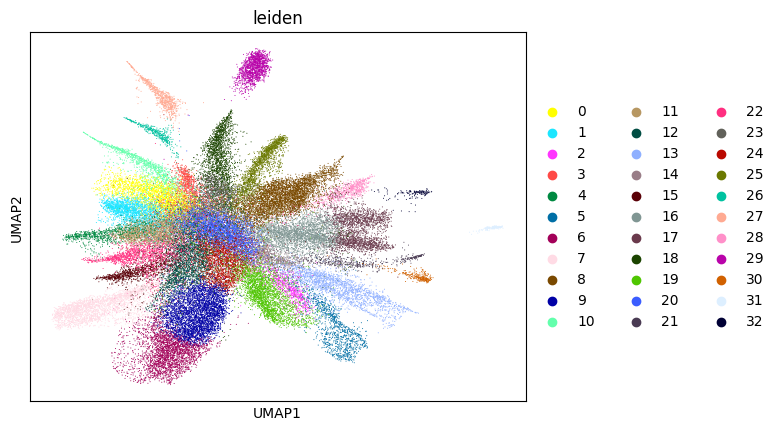

0.42587605351650787 1


100%|██████████| 56867/56867 [01:05<00:00, 874.50it/s]


Starting mt
Starting normalization
Starting PCA
Starting UMAP
Starting Clustering


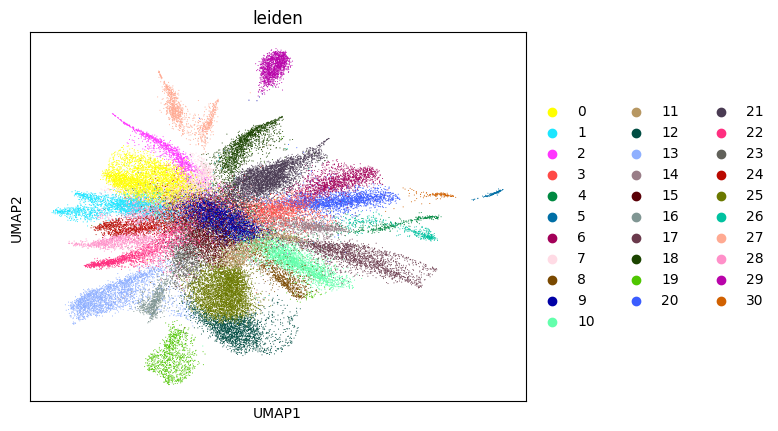

0.6653163073440685 2


100%|██████████| 56867/56867 [01:04<00:00, 885.56it/s] 


Starting mt
Starting normalization
Starting PCA
Starting UMAP
Starting Clustering


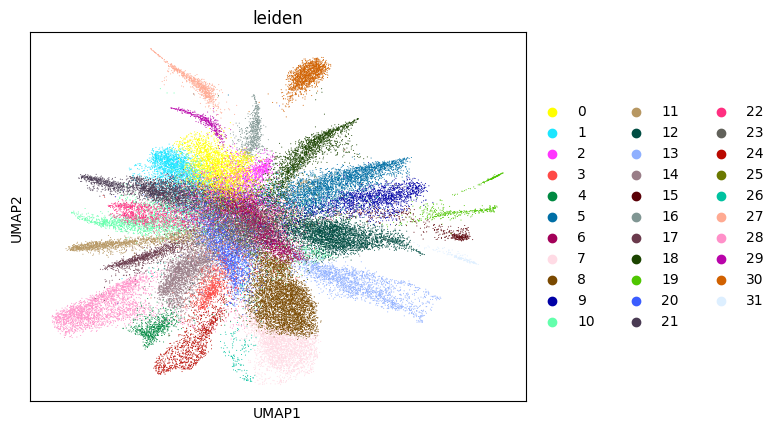

0.692272176364526 3


100%|██████████| 56867/56867 [01:04<00:00, 875.97it/s] 


Starting mt
Starting normalization
Starting PCA
Starting UMAP
Starting Clustering


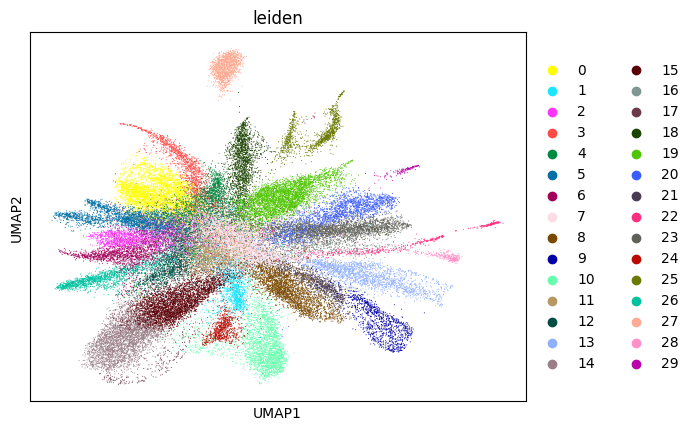

0.7058946412586965 4


100%|██████████| 56867/56867 [01:04<00:00, 882.54it/s] 


Starting mt
Starting normalization
Starting PCA
Starting UMAP
Starting Clustering


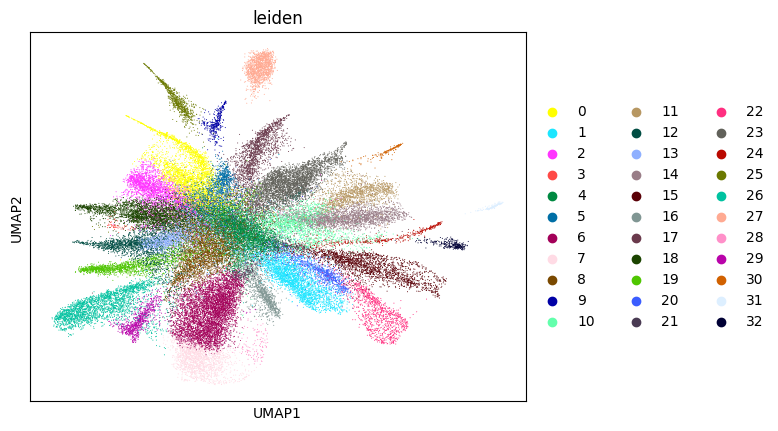

0.7017089650355296 5


100%|██████████| 56867/56867 [01:05<00:00, 874.40it/s]


Starting mt
Starting normalization
Starting PCA
Starting UMAP
Starting Clustering


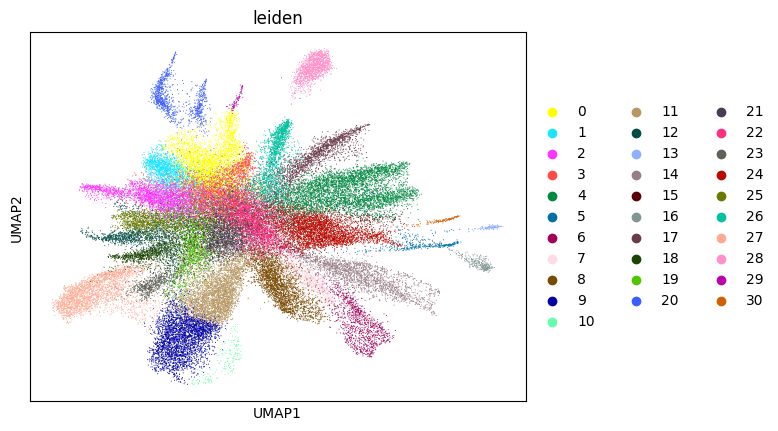

0.6986723859819448 6


In [15]:
su.itering_arragement(adata_sc, adata_raw, adata, so, resolution=2, save_folder = save_path, show = True, keep_previous = False)

Load results here. From this point onward, the SMURF-lite and SMURF-full workflows differ. The lite workflow uses the non-deep-learning shared-spot assignment strategy, whereas the full workflow adds a deep-learning refinement step. This is the last natural checkpoint at which you can switch to the full workflow using the same intermediate objects (`adatas_final`, `cells_final`, and `weights_record`).

In [16]:
adatas_final = sc.read_h5ad(save_path +'adatas.h5ad')

with open(save_path +'cells_final.pkl', 'rb') as file:
    cells_final = pickle.load(file)

with open(save_path +'weights_record.pkl', 'rb') as file:
    weights_record = pickle.load(file)

100%|██████████| 23340/23340 [01:16<00:00, 305.09it/s]


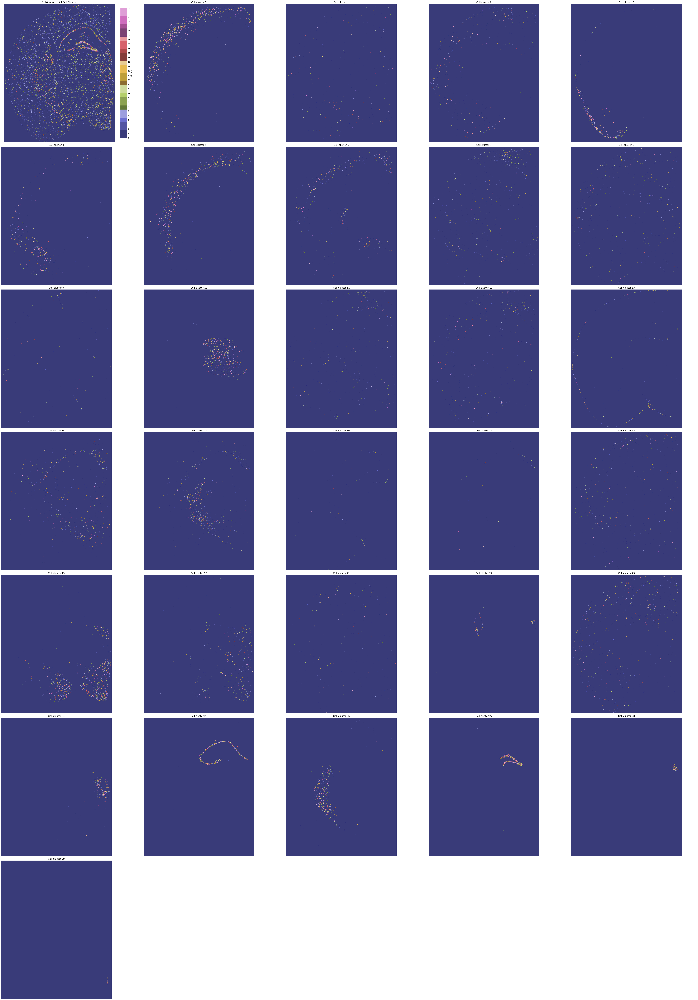

In [17]:
cell_cluster_final = su.return_celltype_plot(adatas_final, so)
su.plot_cellcluster_position(cell_cluster_final, col_num=5)

Here, we generate the final result. By setting `plot = True`, we will create `so.pixels_cells`, which might take more than half an hour. If you do not need this or have already generated `so.pixels_cells`, set `plot = False`.

Here, `adata_sc_final.obs` contains five columns:

- `cell_cluster`: Denotes the cluster assignment from the iteration.
- `cos_simularity`: The cosine similarity of the cell's gene expression with the average expression of its cluster.
- `cell_size`: The number of `2um` spots occupied by this cell.
- `array_row` and `array_col`: The absolute coordinates of the cell, matching the spot locations provided by 10x.


In [18]:
adata_sc_final = su.get_finaldata_fast(cells_final, so, adatas_final, adata, weights_record, plot = True)
adata_sc_final

100%|██████████| 23340/23340 [27:03<00:00, 14.38it/s] 


AnnData object with n_obs × n_vars = 56823 × 9970
    obs: 'cell_cluster', 'cos_simularity', 'cell_size', 'array_row', 'array_col', 'n_counts'
    var: 'gene_ids', 'feature_types'
    uns: 'spatial'
    obsm: 'spatial'

Since we are using the filtered version of the data, if you want to recover the full gene set in the final dataset, you can use the following code:

```python
adata1 = sc.read_10x_mtx(data_path + 'binned_outputs/square_002um/filtered_feature_bc_matrix')
adata1 = adata1[so.df[so.df.in_tissue == 1]['barcode']]
weight_to_celltype = su.calculate_weight_to_celltype(adatas_final, adata1, cells_final, so)
adata_sc_final2 = su.get_finaldata_fast(cells_final, so, adatas_final, adata1, weight_to_celltype, plot=False)
adata_sc_final2
```

Finally, we generate a pixels-to-cell visualization overlaid on the original staining image. Saving this figure can take a long time. Use `save=None` or `save=False` if saving is not needed. High DPI settings also increase runtime; `dpi=1500` is a typical high-resolution setting.

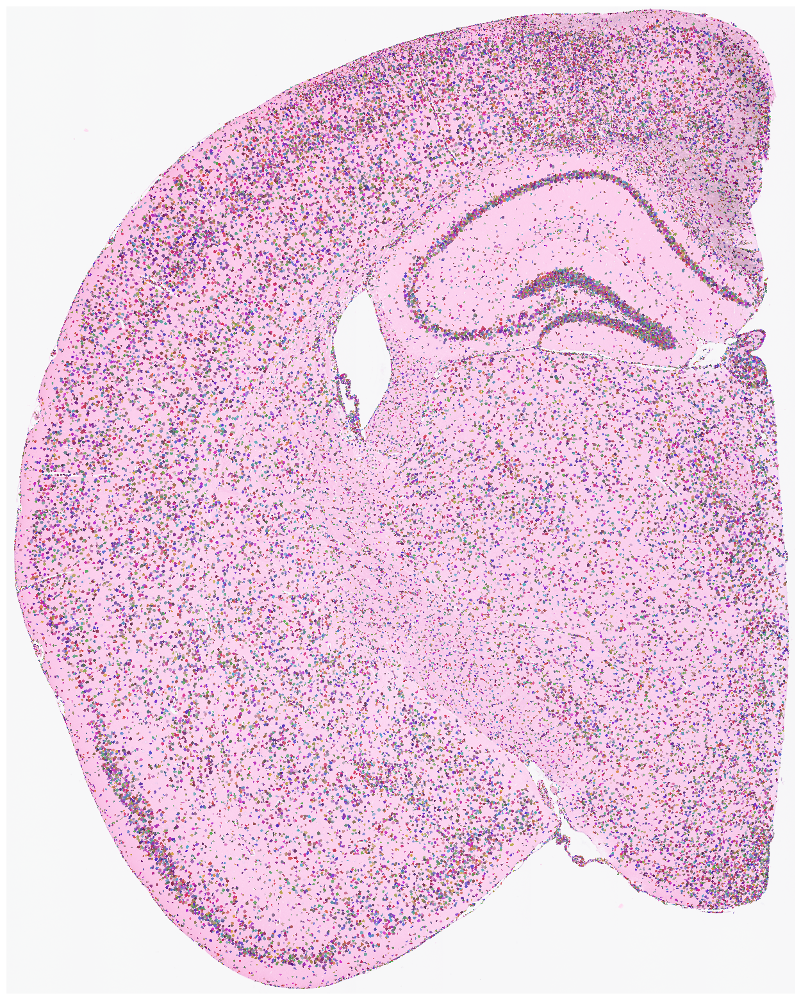

In [19]:
su.plot_results(so.image_temp(), so.pixels_cells, dpi = 1500, save = save_path + 'final_results.pdf')

Save your results here.

Please note that `so` is a very large object because it contains the raw image. If you do not have enough disk space, use the following compressed format instead:

```python
import pickle
import gzip

def save_compressed_pickle(data, filename):
    with gzip.GzipFile(filename, 'wb') as f:
        pickle.dump(data, f, protocol=pickle.HIGHEST_PROTOCOL)

save_compressed_pickle(so, save_path + "so.pkl.gz")
```

You can load your file using this code:
```python
import pickle
import gzip

def load_compressed_pickle(filename):
    with gzip.GzipFile(filename, 'rb') as f:
        return pickle.load(f)

so = load_compressed_pickle(save_path + 'so.pkl.gz')
```


In [20]:
with open(save_path + "so.pkl", 'wb') as f:
    pickle.dump(so, f)

adata_sc_final.write(save_path + "adata_sc_final.h5ad")

In [22]:
adata1 = sc.read_10x_mtx(data_path +'binned_outputs/square_002um/filtered_feature_bc_matrix')
adata1 = adata1[so.df[so.df.in_tissue == 1]['barcode']]
weight_to_celltype = su.calculate_weight_to_celltype(adatas_final, adata1, cells_final, so)
adata_sc_final2 = su.get_finaldata_fast(cells_final, so, adatas_final, adata1, weight_to_celltype, plot = False)

100%|██████████| 1690156/1690156 [04:15<00:00, 6611.70it/s] 


In [23]:
adata_sc_final2.write(save_path + "adata_sc_final2.h5ad")